# Four-model manual Beer Game

[Three simple steps and four prompts](../prompts/FOUR_MODEL_MANUAL/README.md). No API calls. Import the exact returned JSON and authentic transcript; set review flags only after checking adherence. The new joint-context sample is separate from all previous pilots.

In [1]:
from pathlib import Path
import sys, json
import pandas as pd
from IPython.display import display, Markdown, Image
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'src/beergame_study').is_dir())
sys.path.insert(0, str(ROOT / 'src'))
from beergame_study import manual_batch_v4 as batch
from beergame_study import manual_batch_analysis_v4 as analysis
EXP = ROOT / 'experiments/13_weekly_state_api_20261021'
RUN = EXP / 'data' / batch.study_id()
REPORT = EXP / 'reports/four_model_manual'
LEDGER = ROOT / 'experiments/12_pressure_framing_api_20261020/data/api_budget.json'
ledger_before = analysis.sha(LEDGER)
print('Study:', batch.study_id())
print('Returned files can be placed in:', RUN / 'inbox')

Study: manual_batch_v4_e8f534202ca1a55a
Returned files can be placed in: D:\beergame\experiments\13_weekly_state_api_20261021\data\manual_batch_v4_e8f534202ca1a55a\inbox


## Import returned files

Leave this list empty to review existing data. Add one dictionary per response. The JSON and transcript are preserved exactly. Unreviewed/partial files stay in the intake log and cannot enter inference. `website_label` and `reasoning_setting` are your actual selections, not the requested prompt labels.

In [2]:
IMPORTS = []
# Example (replace paths and actual UI labels):
# IMPORTS = [dict(json_path=r'D:\downloaded.json', transcript_path=r'D:\full_transcript.txt',
#    website_label='ACTUAL MODEL LABEL', reasoning_setting='ACTUAL MODE',
#    reviewed=False, fresh_chat_confirmed=False, reviewer='', note='')]
from tqdm.auto import tqdm
for item in tqdm(IMPORTS, desc='Validate and preserve returned batches'):
    receipt = analysis.intake(RUN, **item)
    print(receipt.get('model'), receipt.get('batch_id'), 'eligible:', receipt['eligible'], 'error:', receipt['error'])

Validate and preserve returned batches: 0it [00:00, ?it/s]

,model,reviewed_batches,planned_attempts,chains_per_condition,total_chain_instances
0,gpt_astra,0,40,0,0
1,gpt_sol,0,40,0,0
2,gpt_luna,0,40,0,0
3,claude_sonnet,0,40,0,0


No reviewed new observations yet. H1-H4 remain unestablished.


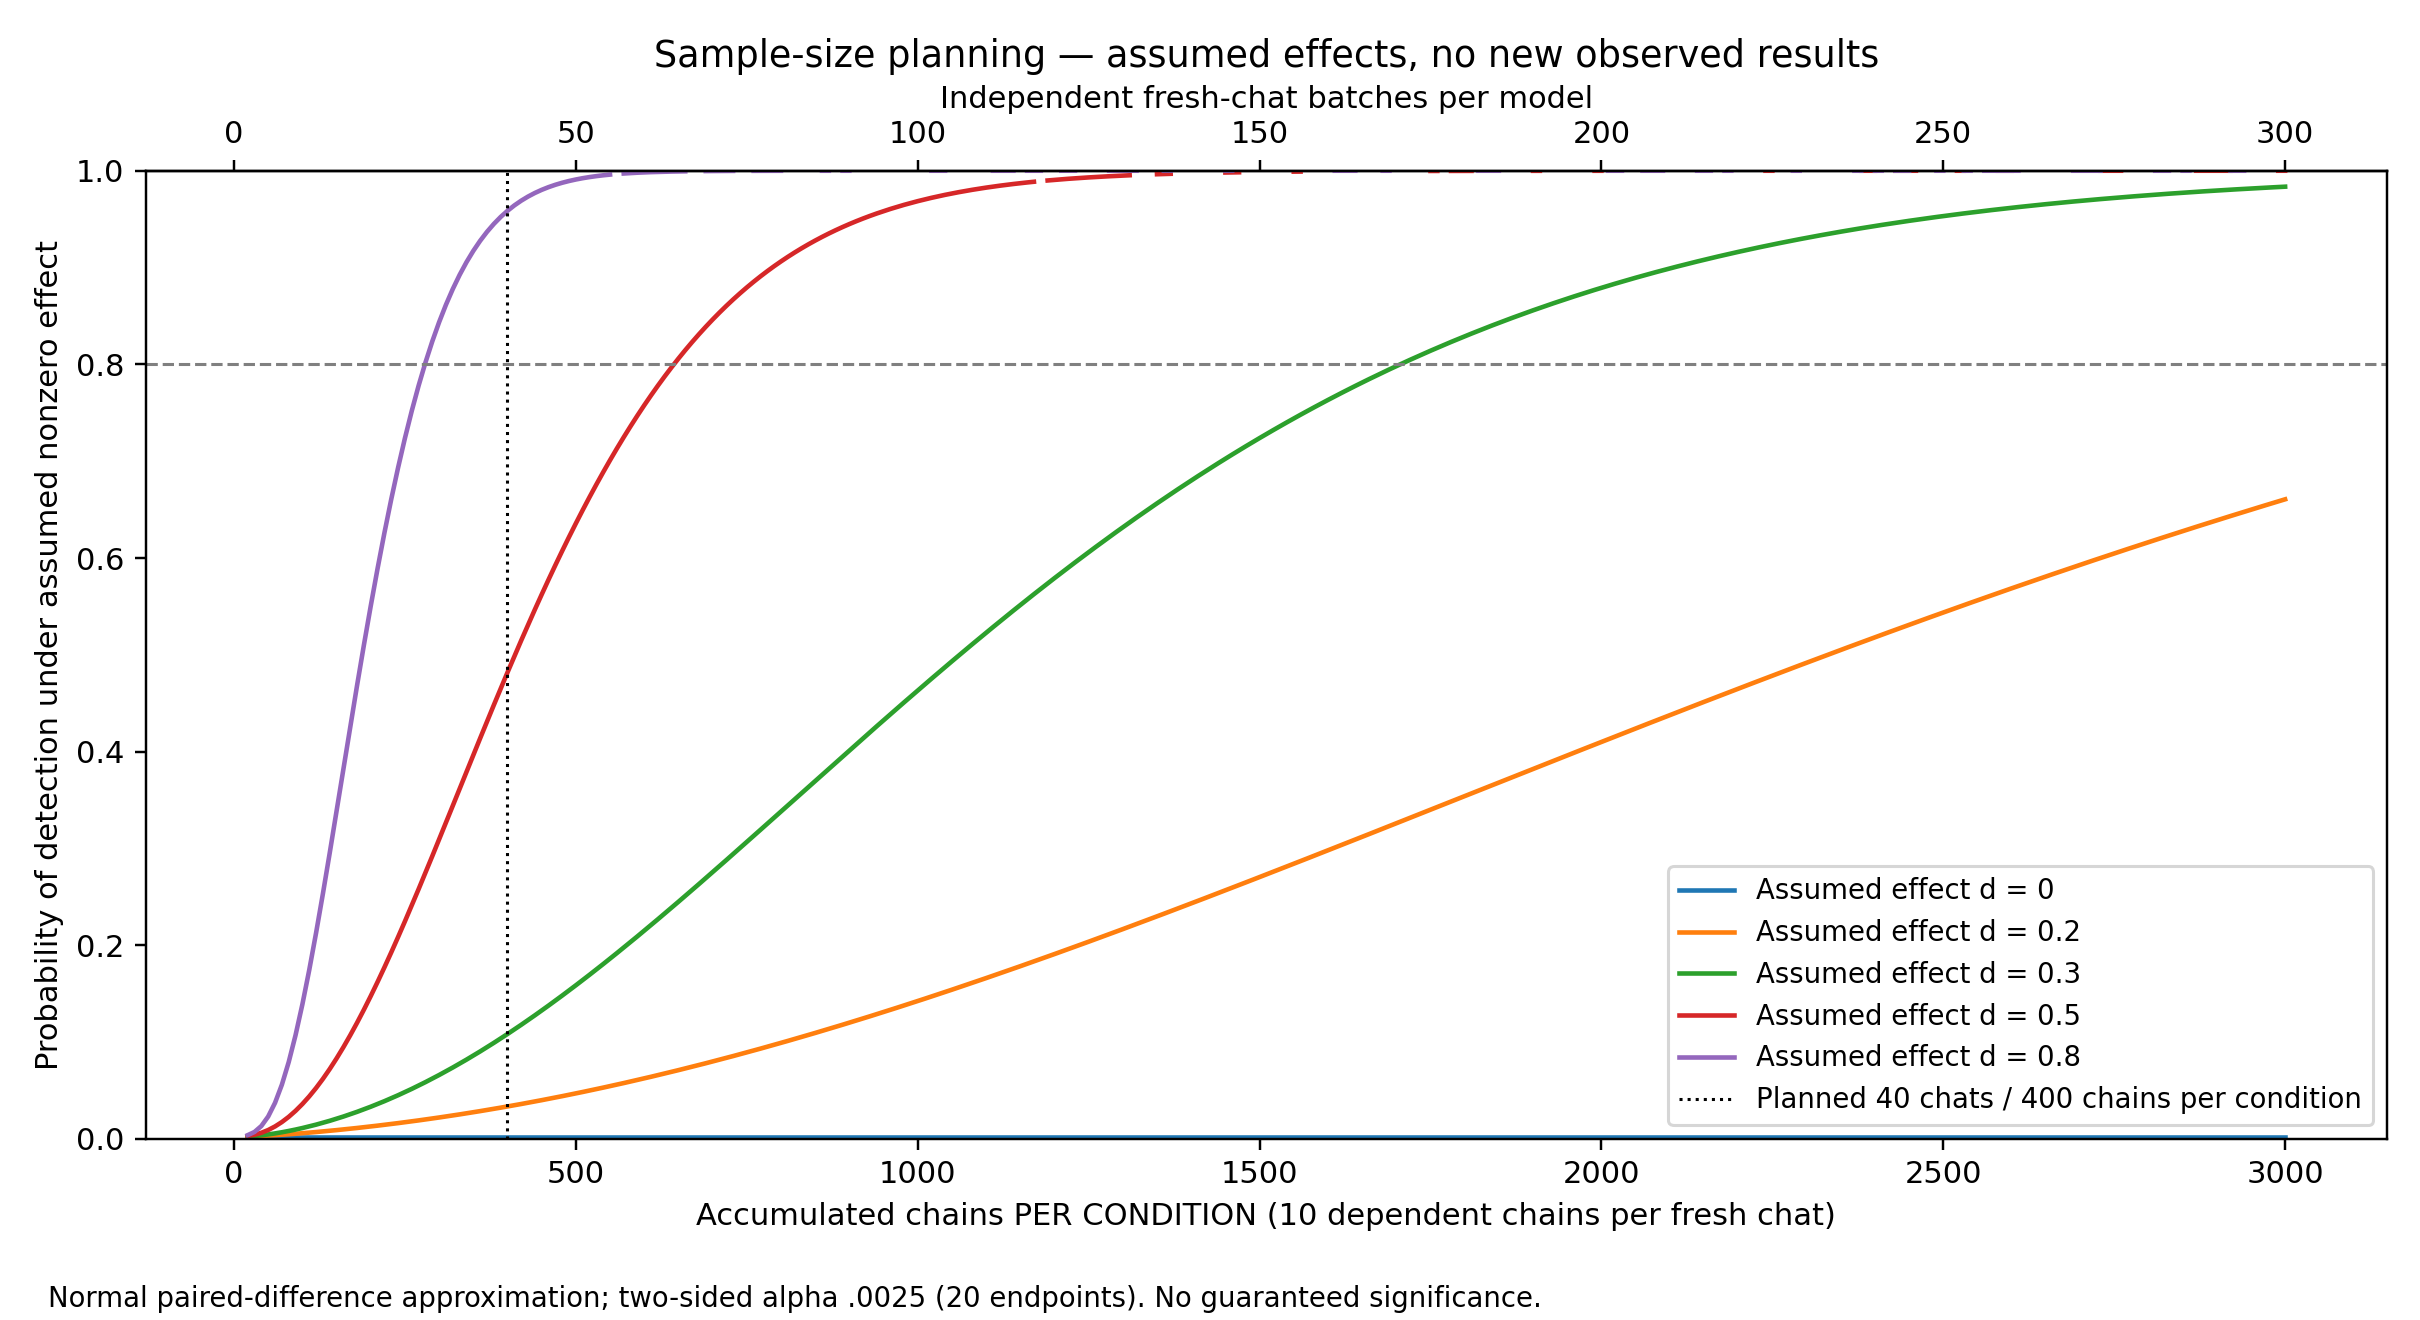

# H1–H4: four-model manual collection

1. Reviewed fresh-chat batches: {'gpt_astra': 0, 'gpt_sol': 0, 'gpt_luna': 0, 'claude_sonnet': 0}. Target: 40 per model; 10 chains per condition per chat.
2. No H1–H4 verification can be claimed from a single batch or an uncollected sample.
3. Observed sweeps use only returned, replayed, transcript-reviewed batches; planning curves use stated hypothetical effects.
4. This simplified design shares all conditions in one context. It tests joint-context AI responses, with possible education carryover; it cannot establish human time-pressure or isolated education effects.

## Where the hypotheses are measured

| Hypothesis | Measurement | Contrast / predicted sign |
|---|---|---|
| H1 | Pipeline-response sensitivity (proxy for outstanding-order use) | B − A < 0 |
| H2 | 24-week holding + backlog cost per chain | B − A > 0 |
| H3 | Pipeline-response sensitivity | C − B > 0 |
| H4a | Mean individual weekly order variance | C − B < 0 |
| H4b | Mean order variance / external demand variance | C − B < 0 |

A = control reading + extra review. B = control + initial committed. C = causal education + initial committed.

[Sample-size planning](SAMPLE_SIZE_PLANNING.png) · [Assumed required samples](required_samples_assuming_effect.csv) · [Extracted results](extracted_results.csv) · [Observed sweep table](observed_sample_size_sweep.csv)

No elapsed human deadline is enforced. Sensitivity is not an identified underweighting coefficient. A model can rationally produce no difference. Within-chat chains, weeks and roles are not independent observations.

Inference is exploratory and conditional on independent fresh chats and symmetric paired differences. Two-sided paired sign flips and Holm correction retain all 20 model/endpoints. Prefixes 1/2/5/10/20/40 are descriptive; no stopping at first significance. A single batch has no inferential p-value or interval. Full-sample inference is planned at 40 chats per model. Pointwise bootstrap intervals are not simultaneous intervals.

Planning assumes normally distributed paired chat differences and d = mean difference / between-chat SD. It uses a paired-t approximation and conservative alpha .05/20; it is not a power guarantee for the sign-flip test. Zero true effect has no sample size that produces reliable support. The old pilot does not estimate the new design's between-chat variance.

Methods: [SciPy noncentral t](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.nct.html).

No new model responses have been collected for this version. An observed significance curve will appear after eligible results arrive.


API ledger unchanged. Planning curves are assumptions, not observed findings.


In [3]:
result = analysis.analyze(RUN, REPORT)
display(pd.DataFrame([dict(model=k, reviewed_batches=v, planned_attempts=40,
                           chains_per_condition=10*v, total_chain_instances=30*v)
                      for k, v in result['eligible_fresh_chat_batches'].items()]))
if result['observations']:
    display(pd.DataFrame(result['observations']))
    display(Image(filename=str(REPORT / 'OBSERVED_H1_H4_SWEEP.png')))
else:
    print('No reviewed new observations yet. H1-H4 remain unestablished.')
display(Image(filename=str(REPORT / 'SAMPLE_SIZE_PLANNING.png')))
display(Markdown((REPORT / 'REPORT.md').read_text(encoding='utf-8')))
assert analysis.sha(LEDGER) == ledger_before
print('API ledger unchanged. Planning curves are assumptions, not observed findings.')